# Sales Data Analysis

Objective:
To analyze sales data and identify sales trends, product performance, regional performance, profitability patterns, and the impact of discounts on business performance.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("superstore.csv")
df.head()

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07 00:00:00.000,CA-2011-130813,...,19,Consumer,2011-01-09 00:00:00.000,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21 00:00:00.000,CA-2011-148614,...,19,Consumer,2011-01-26 00:00:00.000,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,...,21,Consumer,2011-08-09 00:00:00.000,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,...,111,Consumer,2011-08-09 00:00:00.000,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29 00:00:00.000,CA-2011-146969,...,6,Consumer,2011-10-03 00:00:00.000,Standard Class,1.32,California,Paper,2011,North America,40


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  object 
 1   City            51290 non-null  object 
 2   Country         51290 non-null  object 
 3   Customer.ID     51290 non-null  object 
 4   Customer.Name   51290 non-null  object 
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  object 
 7   记录数             51290 non-null  int64  
 8   Order.Date      51290 non-null  object 
 9   Order.ID        51290 non-null  object 
 10  Order.Priority  51290 non-null  object 
 11  Product.ID      51290 non-null  object 
 12  Product.Name    51290 non-null  object 
 13  Profit          51290 non-null  float64
 14  Quantity        51290 non-null  int64  
 15  Region          51290 non-null  object 
 16  Row.ID          51290 non-null  int64  
 17  Sales           51290 non-null 

In [5]:
df.isnull().sum()

Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
记录数               0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     0
State             0
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64

In [6]:
df['Order.Date'] = pd.to_datetime(df['Order.Date'])

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Category        51290 non-null  object        
 1   City            51290 non-null  object        
 2   Country         51290 non-null  object        
 3   Customer.ID     51290 non-null  object        
 4   Customer.Name   51290 non-null  object        
 5   Discount        51290 non-null  float64       
 6   Market          51290 non-null  object        
 7   记录数             51290 non-null  int64         
 8   Order.Date      51290 non-null  datetime64[ns]
 9   Order.ID        51290 non-null  object        
 10  Order.Priority  51290 non-null  object        
 11  Product.ID      51290 non-null  object        
 12  Product.Name    51290 non-null  object        
 13  Profit          51290 non-null  float64       
 14  Quantity        51290 non-null  int64         
 15  Re

In [8]:
df['Month'] = df['Order.Date'].dt.month
df['Month_Name'] = df['Order.Date'].dt.month_name()
df['Year_New'] = df['Order.Date'].dt.year

In [9]:
df[['Order.Date','Month_Name','Year_New']].head()

,Order.Date,Month_Name,Year_New
0,2011-01-07,January,2011
1,2011-01-21,January,2011
2,2011-08-05,August,2011
3,2011-08-05,August,2011
4,2011-09-29,September,2011


In [10]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly_sales = df.groupby('Month_Name')['Sales'].sum().reindex(month_order)
print(monthly_sales)

Month_Name
January       675141
February      543768
March         770519
April         698603
May           904061
June         1269751
July          749423
August       1293852
September    1437432
October      1168220
November     1551319
December     1580816
Name: Sales, dtype: int64


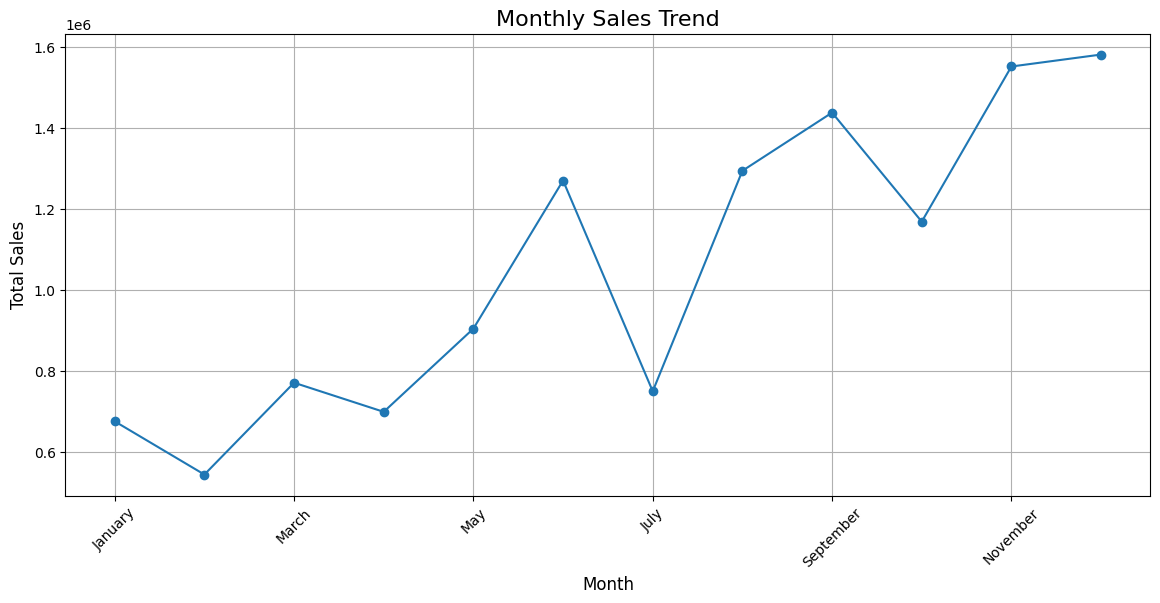

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14,6))
monthly_sales.plot(kind='line', marker='o')
plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

The Sales Trend Analysis shows that Sales gradually increased throughout the year.
The Highest Sales were observed in November and December, indicating strong festive season demand.
February recorded the lowest Sales.
Overall, the business experienced significant growth during the second half of the year.

In [12]:
top_products = df.groupby('Product.Name')['Sales'].sum().sort_values(ascending=False).head(10)
print(top_products)

Product.Name
Apple Smart Phone, Full Size                                86936
Cisco Smart Phone, Full Size                                76441
Motorola Smart Phone, Full Size                             73159
Nokia Smart Phone, Full Size                                71904
Canon imageCLASS 2200 Advanced Copier                       61600
Hon Executive Leather Armchair, Adjustable                  58200
Office Star Executive Leather Armchair, Adjustable          50667
Harbour Creations Executive Leather Armchair, Adjustable    50120
Samsung Smart Phone, Cordless                               48654
Nokia Smart Phone, with Caller ID                           47880
Name: Sales, dtype: int64


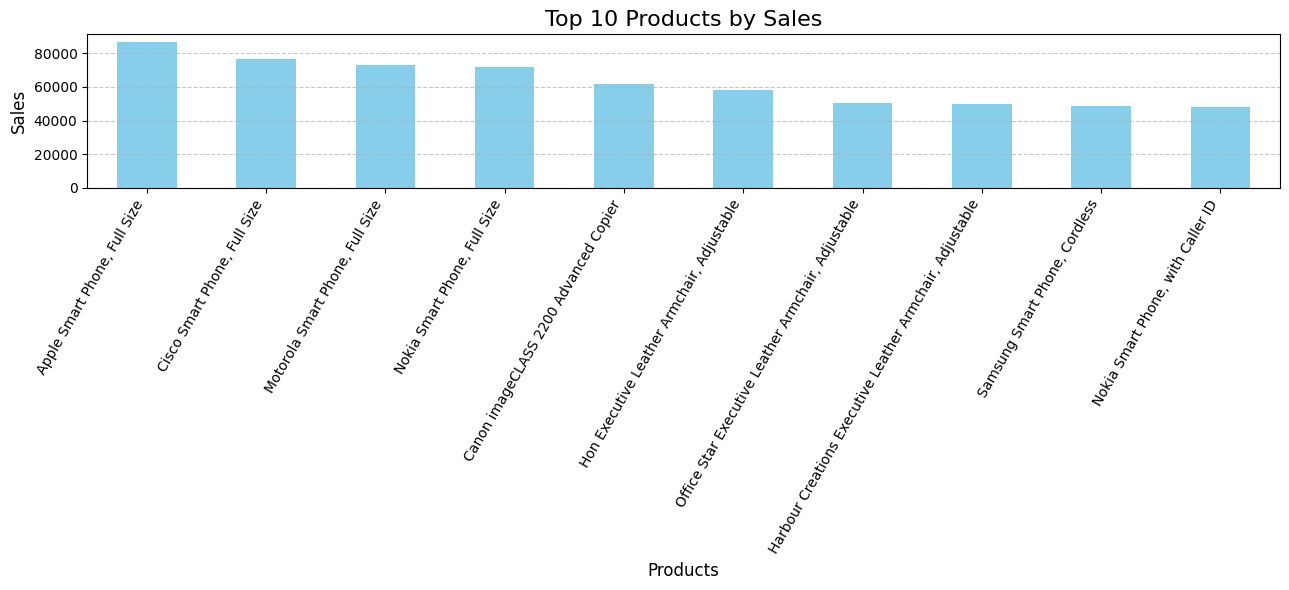

In [13]:
plt.figure(figsize=(13,6))
top_products.plot(kind='bar', color='skyblue')
plt.title("Top 10 Products by Sales", fontsize=16)
plt.xlabel("Products", fontsize=12)
plt.ylabel("Sales", fontsize=12)
plt.xticks(rotation=60, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The Top Prouct Sales Analysis revealed that Smartphone Products dominated Overall Sales Performance. Apple Smart Phone (Full Size) generated the Highest Sales Revenue among all Products, followed by Cisco, Motorola, and Nokia SmartPhones. Additionally, Executive Leather Armchairs also showed Strong Performance, indicating significant customer demand in both technology and office furniture categories. This Analysis Highlights the company's Strongest Product segments and helps identify High Performing Products contributing to Overall Business Growth.

In [14]:
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
print(region_sales)

Region
Central           2822399
South             1600960
North             1248192
Oceania           1100207
Southeast Asia     884438
North Asia         848349
EMEA               806184
Africa             783776
Central Asia       752839
West               725514
East               678834
Caribbean          324281
Canada              66932
Name: Sales, dtype: int64


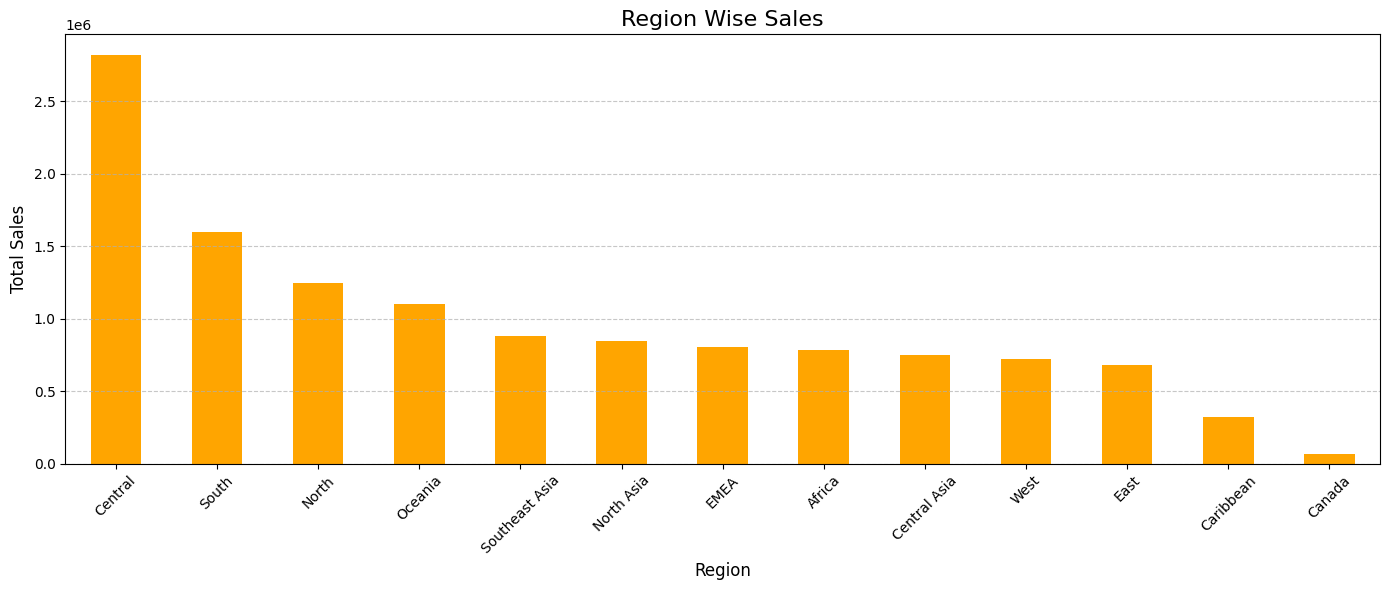

In [15]:
plt.figure(figsize=(14,6))

region_sales.plot(kind='bar', color='orange')

plt.title("Region Wise Sales", fontsize=16)
plt.xlabel("Region", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

plt.xticks(rotation=45)

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()

plt.show()

The Cental Region generated The Highest Sales among all regions, followed by South and North regions.
Canada and Carribean regions recorded comparatively Lower Sales Performance.
This Analysis indicates Strong Business performance in major regions while Highlighting for Improvement in Lower-Performing Markets.

In [16]:
top_profit_products = df.groupby('Product.Name')['Profit'].sum().sort_values(ascending=False).head(10)
print(top_profit_products)

Product.Name
Canon imageCLASS 2200 Advanced Copier                       25199.9280
Cisco Smart Phone, Full Size                                17238.5206
Motorola Smart Phone, Full Size                             17027.1130
Hoover Stove, Red                                           11807.9690
Sauder Classic Bookcase, Traditional                        10672.0730
Harbour Creations Executive Leather Armchair, Adjustable    10427.3260
Nokia Smart Phone, Full Size                                 9938.1955
Cisco Smart Phone, with Caller ID                            9786.6408
Nokia Smart Phone, with Caller ID                            9465.3257
Belkin Router, USB                                           8955.0180
Name: Profit, dtype: float64


The profit analysis revealed that the Canon imageCLASS 2200 Advanced Copier was the most profitable product, generating the highest overall profit. Smartphones from brands such as Cisco, Motorola, and Nokia also contributed significantly to profitability, indicating strong demand and healthy profit margins in the technology segment. Additionally, office furniture products such as executive armchairs and bookcases generated substantial profits, highlighting their importance to the company's overall financial performance.

In [17]:
category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
print(category_sales)

Category
Technology         4744691
Furniture          4110884
Office Supplies    3787330
Name: Sales, dtype: int64


The category-wise sales analysis showed that Technology was the highest revenue-generating category, contributing the largest share of total sales. Furniture ranked second, demonstrating strong customer demand across office and home furnishing products. Office Supplies generated the lowest sales among the three categories, although it still contributed significantly to overall business revenue. The results indicate that Technology products are the primary drivers of sales growth for the business.

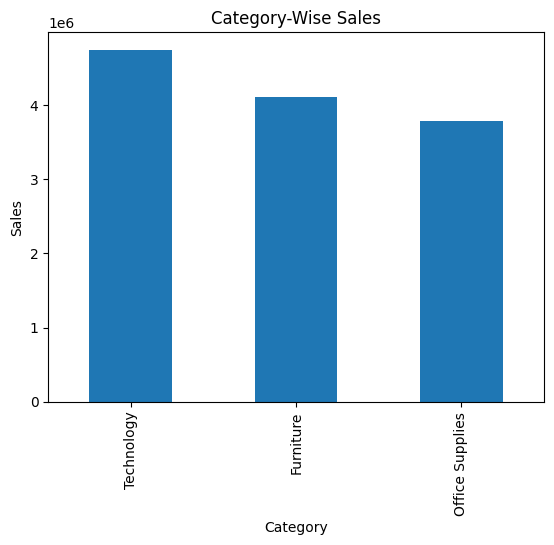

In [18]:
category_sales.plot(kind='bar')
plt.title("Category-Wise Sales")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.show()

In [19]:
category_profit = df.groupby('Category')['Profit'].sum().sort_values(ascending=False)
print(category_profit)

Category
Technology         663778.73318
Office Supplies    518473.83430
Furniture          285204.72380
Name: Profit, dtype: float64


The category-wise profit analysis revealed that Technology was the most profitable category, generating the highest overall profit. Although Furniture recorded strong sales performance, its profitability was significantly lower than expected, indicating comparatively lower profit margins. Office Supplies generated lower sales than Furniture but delivered substantially higher profits, suggesting a more efficient and profitable product mix. These findings indicate that Technology and Office Supplies contribute most effectively to the company's profitability.

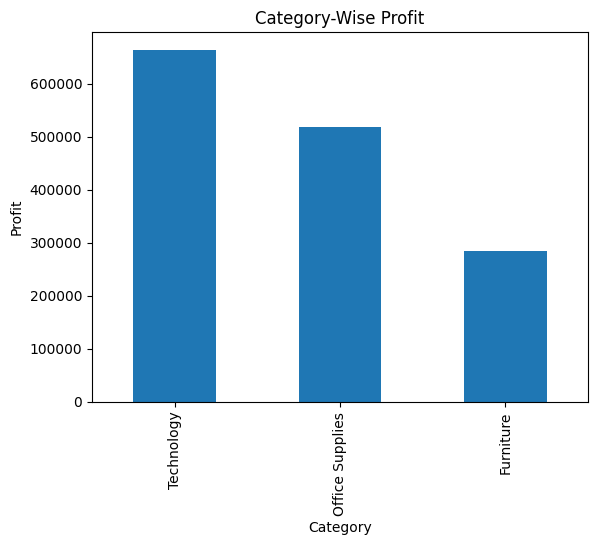

In [20]:
category_profit.plot(kind='bar')
plt.title("Category-Wise Profit")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.show()

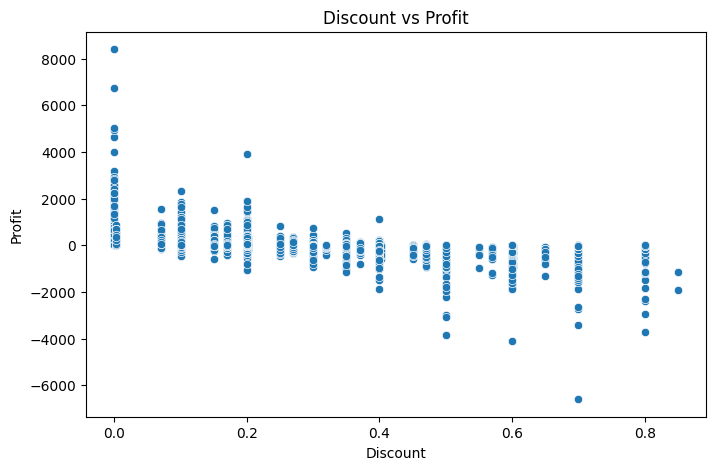

In [21]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x='Discount', y='Profit')

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()

The Discount vs Profit analysis indicates that higher discounts generally lead to lower profitability. Most high-profit transactions occurred at low or zero discount levels, while many high-discount transactions resulted in reduced profits or losses. This suggests that excessive discounting negatively impacts business profitability and should be carefully managed to maintain healthy profit margins.

# Conclusion

The analysis revealed that Technology was the strongest performing category in terms of both sales and profit. Smartphone products generated the highest revenue and profitability among all products. The Central region recorded the highest sales, while Canada and Caribbean showed comparatively lower performance. Monthly sales trends indicated stronger sales during the later months of the year, particularly in November and December. Furthermore, the discount analysis showed that excessive discounting can negatively impact profitability. Overall, the business demonstrates strong growth potential with Technology products serving as its primary revenue driver.